# **Training and Evaluating the CNN**

**Objective:** train the convolutional network on the training set, choose nothing with the test set, and measure it once on the test set at the end.

**Outputs:** `outputs/cherry_leaf_cnn.keras` (the model the app loads), `outputs/metrics.json` (the figures the app shows) and the plots in `outputs/figures/`.

In [1]:
from pathlib import Path

# The notebooks live in notebooks/; every path is relative to the repository root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "inputs" / "raw" / "cherry-leaves"
PREPARED = ROOT / "inputs" / "prepared"
OUTPUTS = ROOT / "outputs"
print("Repository root:", ROOT.name)

import json
import logging
import os
import warnings

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import keras
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

SEED = 42
IMAGE_SIZE = (50, 50)
BATCH_SIZE = 20
EPOCHS = 15
keras.utils.set_random_seed(SEED)
# Two harmless messages: tf.data datasets ignore `shuffle`, and Windows has no TensorFlow GPU
warnings.filterwarnings("ignore", message=".*shuffle=True.*")
logging.getLogger("tensorflow").setLevel(logging.ERROR)
(OUTPUTS / "figures").mkdir(parents=True, exist_ok=True)
print("Keras", keras.__version__)

Repository root: mildew


Keras 3.15.1


## 1. Load the three sets

The class comes from the folder name, in alphabetical order: `healthy` = 0, `powdery_mildew` = 1.

In [2]:
def load(name, shuffle):
    return keras.utils.image_dataset_from_directory(
        PREPARED / name, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
        label_mode="binary", shuffle=shuffle, seed=SEED)

train_ds = load("train", shuffle=True)
validation_ds = load("validation", shuffle=False)
test_ds = load("test", shuffle=False)
print("Classes:", train_ds.class_names)

Found 3194 files belonging to 2 classes.


Found 438 files belonging to 2 classes.


Found 879 files belonging to 2 classes.


Classes: ['healthy', 'powdery_mildew']


## 2. The model

The same architecture as in 2024: two convolutional blocks, a dense layer of 512 and dropout. The only change is that the rescaling of pixels to [0, 1] is now a layer of the model, so the app sends the image as it is and cannot forget that step.

In [3]:
model = keras.Sequential([
    keras.Input(shape=IMAGE_SIZE + (3,)),
    keras.layers.Rescaling(1.0 / 255),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D(2, 2),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D(2, 2),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 50, 50, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7744)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,965,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,985,345 (15.20 MB)

 Trainable params: 3,985,345 (15.20 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Training

15 epochs, as in 2024. The validation set is watched during training; the test set is not touched.

In [4]:
history = model.fit(train_ds, validation_data=validation_ds, epochs=EPOCHS, verbose=2)

Epoch 1/15


160/160 - 10s - 65ms/step - accuracy: 0.9505 - loss: 0.1193 - val_accuracy: 0.9932 - val_loss: 0.0145


Epoch 2/15


160/160 - 7s - 43ms/step - accuracy: 0.9944 - loss: 0.0216 - val_accuracy: 0.9909 - val_loss: 0.0460


Epoch 3/15


...

160/160 - 6s - 37ms/step - accuracy: 1.0000 - loss: 1.2772e-04 - val_accuracy: 0.9977 - val_loss: 0.0168


Epoch 14/15


160/160 - 6s - 37ms/step - accuracy: 1.0000 - loss: 6.2462e-05 - val_accuracy: 0.9977 - val_loss: 0.0168


Epoch 15/15


160/160 - 6s - 37ms/step - accuracy: 1.0000 - loss: 3.9092e-05 - val_accuracy: 0.9977 - val_loss: 0.0182


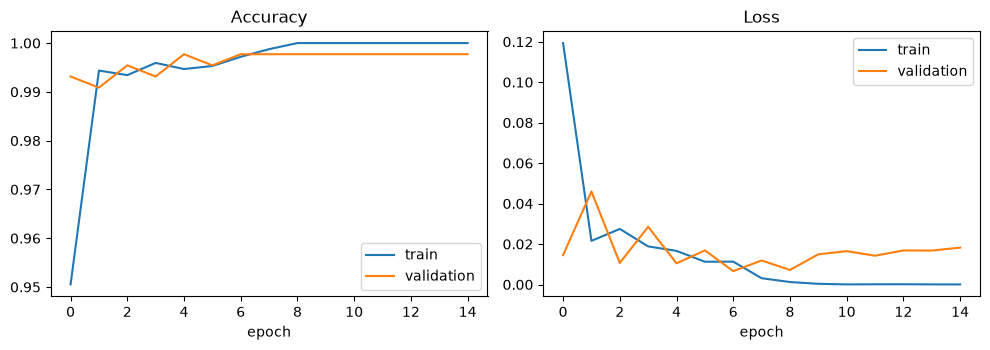

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
for key, label in (("accuracy", "train"), ("val_accuracy", "validation")):
    ax1.plot(history.history[key], label=label)
for key, label in (("loss", "train"), ("val_loss", "validation")):
    ax2.plot(history.history[key], label=label)
ax1.set_title("Accuracy"); ax2.set_title("Loss")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
fig.savefig(OUTPUTS / "figures" / "learning_curves.png", dpi=120)
plt.show()

## 4. Evaluation on the test set

One measurement, at the end, on images the model has never seen in any form.

In [6]:
y_true = np.concatenate([labels.numpy().ravel() for _, labels in test_ds]).astype(int)
probabilities = model.predict(test_ds, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

print(f"Test accuracy: {test_accuracy:.4f}  ({int((y_true != y_pred).sum())} errors in {len(y_true)} images)")
print()
print(classification_report(y_true, y_pred, target_names=train_ds.class_names, digits=4))

Test accuracy: 1.0000  (0 errors in 879 images)

                precision    recall  f1-score   support

       healthy     1.0000    1.0000    1.0000       457
powdery_mildew     1.0000    1.0000    1.0000       422

      accuracy                         1.0000       879
     macro avg     1.0000    1.0000    1.0000       879
  weighted avg     1.0000    1.0000    1.0000       879



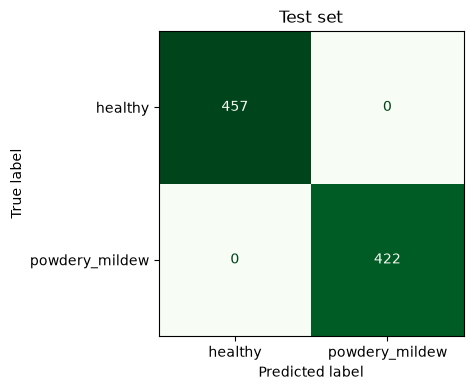

In [7]:
cm = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(cm, display_labels=train_ds.class_names)
fig, ax = plt.subplots(figsize=(4.6, 4))
display.plot(ax=ax, colorbar=False, cmap="Greens")
ax.set_title("Test set")
plt.tight_layout()
fig.savefig(OUTPUTS / "figures" / "confusion_matrix.png", dpi=120)
plt.show()

## 5. Is a perfect score believable?

A very high score is a reason for suspicion before it is a reason for pride. Notebook 02 already dropped exact duplicates; this cell looks for **near** duplicates: the same photo recompressed or slightly changed. Each image gets a 64-bit difference hash, and every test image is compared with every original training image. A distance of 0–2 bits means practically the same picture.

In [8]:
from PIL import Image

def dhash(path):
    pixels = np.asarray(Image.open(path).convert("L").resize((9, 8), Image.Resampling.LANCZOS), dtype=float)
    return (pixels[:, 1:] > pixels[:, :-1]).ravel()

near_duplicates = {}
for label in train_ds.class_names:
    train_hashes = np.array([dhash(p) for p in (PREPARED / "train" / label).glob(f"{label}_*.jpg")])
    nearest = np.array([(train_hashes != dhash(p)).sum(axis=1).min() for p in (PREPARED / "test" / label).iterdir()])
    near_duplicates[label] = int((nearest <= 2).sum())
    print(f"{label}: {len(nearest)} test images · nearest training image ≤2 bits away: {near_duplicates[label]} · "
          f"median distance {np.median(nearest):.0f} bits")

healthy: 457 test images · nearest training image ≤2 bits away: 0 · median distance 10 bits


powdery_mildew: 422 test images · nearest training image ≤2 bits away: 1 · median distance 13 bits


Practically no test image has a twin in training. The score is not leakage: this dataset is easy (one leaf per photo, plain background, even light). What it does **not** say is how the model would do with photos taken in a real plantation; that would need other data.

## 6. Save the model and the figures

The app reads both files: it never shows a number that this notebook did not write.

In [9]:
model.save(OUTPUTS / "cherry_leaf_cnn.keras")
metrics = {
    "test_accuracy": round(float(test_accuracy), 4),
    "test_loss": round(float(test_loss), 4),
    "test_images": int(len(y_true)),
    "test_errors": int((y_true != y_pred).sum()),
    "confusion_matrix": cm.tolist(),
    "test_near_duplicates_in_train": sum(near_duplicates.values()),
    "class_names": train_ds.class_names,
    "split": "70/10/20 per class",
    "seed": SEED,
    "epochs": EPOCHS,
    "image_size": list(IMAGE_SIZE),
    "keras": keras.__version__,
}
(OUTPUTS / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(json.dumps(metrics, indent=2))

{
  "test_accuracy": 1.0,
  "test_loss": 0.0001,
  "test_images": 879,
  "test_errors": 0,
  "confusion_matrix": [
    [
      457,
      0
    ],
    [
      0,
      422
    ]
  ],
  "test_near_duplicates_in_train": 1,
  "class_names": [
    "healthy",
    "powdery_mildew"
  ],
  "split": "70/10/20 per class",
  "seed": 42,
  "epochs": 15,
  "image_size": [
    50,
    50
  ],
  "keras": "3.15.1"
}
